## Interval Analysis

In [2]:
import torch
print(torch.__version__)
print(torch.__file__)

2.5.1
/opt/anaconda3/envs/ml/lib/python3.12/site-packages/torch/__init__.py


In [3]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt
from bound_propagation import BoundModelFactory, HyperRectangle

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("mps")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


# From https://github.com/Zinoex/bound_propagation/blob/main/examples/fashion_mnist.py as provided in instructions (hope that is okay)
# BoundFactory does not recognize Flatten layer so we have to transform the data while downloading

transform = transforms.Compose([
    transforms.PILToTensor(),
    transforms.ConvertImageDtype(torch.float),
    transforms.Lambda(torch.flatten)
])

target_transform = transforms.Compose([])

## Dataloaders
train_dataset = datasets.MNIST('mnist_data_transformed/', train=True, download=True, transform=transform, target_transform=target_transform)
test_dataset = datasets.MNIST('mnist_data_transformed/', train=False, download=True, transform=transform, target_transform=target_transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class Net(nn.Sequential):
    def __init__(self, *args):
        if args:
            super().__init__(*args)
        else:
            super().__init__(
                nn.Linear(784, 50), nn.ReLU(),
                nn.Linear(50, 50), nn.ReLU(),
                nn.Linear(50, 50), nn.ReLU(),
                nn.Linear(50, 10),
            )
    # def forward(self, x):
    #     x = x.view((-1, 28*28))
    #     x = F.relu(self.fc(x))
    #     x = F.relu(self.fc2(x))
    #     x = F.relu(self.fc3(x))
    #     x = self.fc4(x)

    #     # x = F.softmax(x, dim=-1) # added softmax for probabilities
    #     return x
    
model = Net().to(device)
model.train()

# hidden_network = model[:-1]
# final_layer = model[-1]
# factory = BoundModelFactory()
# ibp_model = factory.build(hidden_network)
# ibp_model.train()

Net(
  (0): Linear(in_features=784, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=50, bias=True)
  (3): ReLU()
  (4): Linear(in_features=50, out_features=50, bias=True)
  (5): ReLU()
  (6): Linear(in_features=50, out_features=10, bias=True)
)

In [11]:
def elision_layer(model, final_layer, images, labels, eps):
    bounds = model.ibp(HyperRectangle.from_eps(images, eps))
    lower = bounds.lower # [batch, features]
    upper = bounds.upper # [batch, features]

    W = final_layer.weight # [n_classes, features]
    W_y = W[labels] # [batch, features]
    b = final_layer.bias # [n_classes] .... one bias per class
    b_y = b[labels] # [batch] ..... one bias per image

    W_diff = W.unsqueeze(0) - W_y.unsqueeze(1) # [batch, n_classes, features]
    b_diff = b.unsqueeze(0) - b_y.unsqueeze(1) # [batch, n_classes]

    # we want max difference
    # for positive weight we want to multiply by upper bound to maximize value
        # even if upper bound is negative when multiplied by positive weight it will be larger than lower bound * weight
    positive_term = W_diff.clamp(min=0) * upper.unsqueeze(1) # [batch, n_classes, features]
    positive_term = positive_term.sum(dim=2) # linear layer summation = [batch, n_classes]

    # for negative differences we want to multiply by lower bound
        # -4 weight versus [-4, -2] --> in this case multiplying by lower bound = larger value than multiplying by upper bound
    negative_term = W_diff.clamp(max=0) * lower.unsqueeze(1)
    negative_term = negative_term.sum(dim=2)

    max_diff = positive_term + negative_term + b_diff # [batch, n_classes]
    return max_diff


In [12]:
def clip_box(x, delta):
    # Make x + delta an image in [0, 1]. This never increases |delta_i|.
    return (x + delta).clamp(0, 1) - x


def input_grad(model, x, delta, y):
    delta = delta.detach().requires_grad_(True)
    loss = F.cross_entropy(model(x + delta), y, reduction="sum")
    (grad,) = torch.autograd.grad(loss, delta)
    return grad.detach()

def pgd_linf(model, x, y, eps, alpha, steps, rand_init=True):
    # TODO: implement L-infinity PGD (use input_grad and clip_box)

    if rand_init:
      delta = torch.empty_like(x).uniform_(-eps, eps) #LK: check range -- uniform, -[eps, eps]
    else:
      delta = torch.zeros_like(x)

    delta = clip_box(x, delta)

    for _ in range(steps):
      grad = input_grad(model, x, delta, y)
      delta = delta + alpha * grad.sign()
      delta = clip_box(x, delta.clamp(-eps, eps))

      #LK: do we have to stop early

    return (x + delta).detach()

In [13]:
def train_model(model, num_epochs, is_ibp):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9) # TODO should optimizer change

    if is_ibp:
        hidden_network = model[:-1]
        final_layer = model[-1]
        factory = BoundModelFactory()
        ibp_model = factory.build(hidden_network).to(device)

    k = 1.0
    eps = 0.0
    total_time = 0.0

    for epoch in range(num_epochs):

        if device.type == "mps":
            torch.mps.synchronize()
        start_time = time.perf_counter()

        model.train()

        if is_ibp:
            ibp_model.train()

        running_loss = 0.0

        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            cross_entropy = criterion(outputs, labels)

            if is_ibp:
                logits = elision_layer(ibp_model, final_layer, images, labels, eps)
                loss = k * cross_entropy + (1 - k) * criterion(logits, labels)
            else:
                loss = cross_entropy


            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        k = max(k - 0.1, 0.5) # 5 epochs to reach
        eps = min(eps + 0.01, 0.1) # 10 epochs to reach

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

        if device.type == "mps":
            torch.mps.synchronize()
        epoch_time = time.perf_counter() - start_time
        total_time += epoch_time

        print(f'Time for epoch: {epoch_time}')

    print(f'Total time: {total_time}')


def test_model(model, inc_robust):
    model.eval()

    correct = 0
    total = 0
    robust = 0

    steps = 10
    eps = 8 / 255
    alpha = 2.5 * eps / steps

    for data in test_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)

        with torch.no_grad():
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        if inc_robust:
            x_adv = pgd_linf(model, images, labels, eps, alpha, steps, False)
            with torch.no_grad():
                robust += (model(x_adv).argmax(1) == labels).sum().item()
                    
    print(f'Accuracy on images: {100 * correct / total}')
    if inc_robust:
        print(f'Robust accuracy on images: {100 * robust / total}')

In [14]:
# Checking training time for regular model
train_model(model, 20, False)

Epoch 1/20, Loss: 2.247
Time for epoch: 13.56055175000074
Epoch 2/20, Loss: 1.203
Time for epoch: 10.24439274999986
Epoch 3/20, Loss: 0.522
Time for epoch: 10.947373166999569
Epoch 4/20, Loss: 0.401
Time for epoch: 9.79931229200065
Epoch 5/20, Loss: 0.353
Time for epoch: 12.747512625000127
Epoch 6/20, Loss: 0.320
Time for epoch: 14.3243202499998
Epoch 7/20, Loss: 0.295
Time for epoch: 11.912963249999848
Epoch 8/20, Loss: 0.270
Time for epoch: 9.280257208999501
Epoch 9/20, Loss: 0.249
Time for epoch: 10.072974749999958
Epoch 10/20, Loss: 0.228
Time for epoch: 9.123667291999482
Epoch 11/20, Loss: 0.209
Time for epoch: 9.66849908400036
Epoch 12/20, Loss: 0.193
Time for epoch: 8.883167750000212
Epoch 13/20, Loss: 0.179
Time for epoch: 9.72877170799984
Epoch 14/20, Loss: 0.168
Time for epoch: 7.770800917000088
Epoch 15/20, Loss: 0.158
Time for epoch: 6.679369666000639
Epoch 16/20, Loss: 0.150
Time for epoch: 6.372635083000205
Epoch 17/20, Loss: 0.142
Time for epoch: 6.853203791999476
Epoch 

In [17]:
# Checking training time for IBP trained model
train_model(model, 20, True)
# Reporting standard and robust accuracy against PGD attack
test_model(model, True)

Epoch 1/20, Loss: 0.120
Time for epoch: 31.03717987500022
Epoch 2/20, Loss: 0.805
Time for epoch: 40.52765345899934
Epoch 3/20, Loss: 0.817
Time for epoch: 32.9148848750001
Epoch 4/20, Loss: 0.850
Time for epoch: 26.923490666999896
Epoch 5/20, Loss: 0.937
Time for epoch: 22.350869959000192
Epoch 6/20, Loss: 1.052
Time for epoch: 20.980967958999827
Epoch 7/20, Loss: 1.075
Time for epoch: 20.850353833000554
Epoch 8/20, Loss: 1.118
Time for epoch: 20.374719374999586
Epoch 9/20, Loss: 1.168
Time for epoch: 22.319430040999578
Epoch 10/20, Loss: 1.223
Time for epoch: 21.092251207999652
Epoch 11/20, Loss: 1.280
Time for epoch: 21.958588999999847
Epoch 12/20, Loss: 1.223
Time for epoch: 21.28048737500012
Epoch 13/20, Loss: 1.182
Time for epoch: 22.414867540999694
Epoch 14/20, Loss: 1.151
Time for epoch: 20.656556375000036
Epoch 15/20, Loss: 1.126
Time for epoch: 20.955925334000312
Epoch 16/20, Loss: 1.105
Time for epoch: 28.819254125000043
Epoch 17/20, Loss: 1.086
Time for epoch: 39.9270705830

### Write the interval analysis for the simple model

In [ ]:
# !pip install bound-propagation

Epsilon: 0.009999999776482582. Verified accuracy on images: 82.73


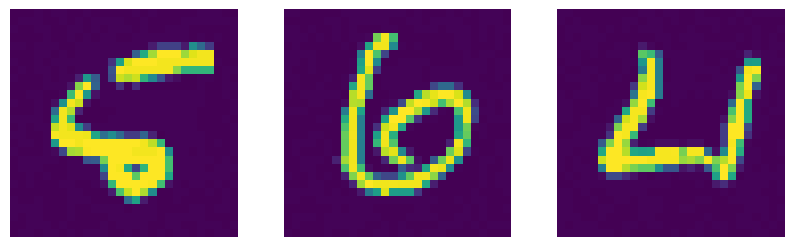

Epsilon: 0.019999999552965164. Verified accuracy on images: 78.33


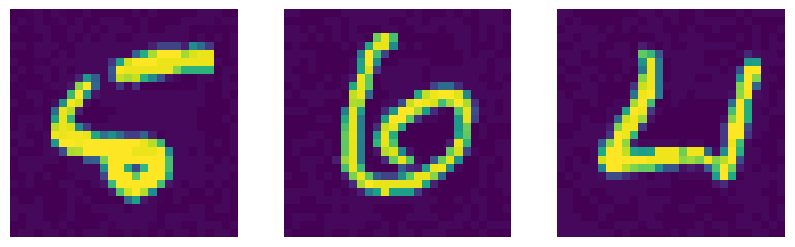

Epsilon: 0.030000001192092896. Verified accuracy on images: 73.02


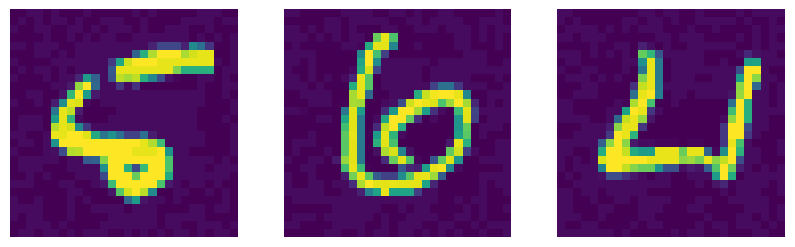

Epsilon: 0.04000000283122063. Verified accuracy on images: 66.78


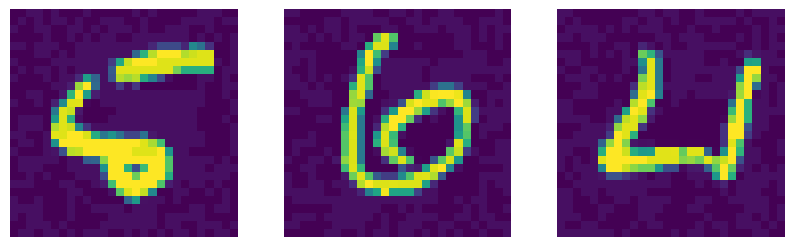

Epsilon: 0.05000000447034836. Verified accuracy on images: 60.24


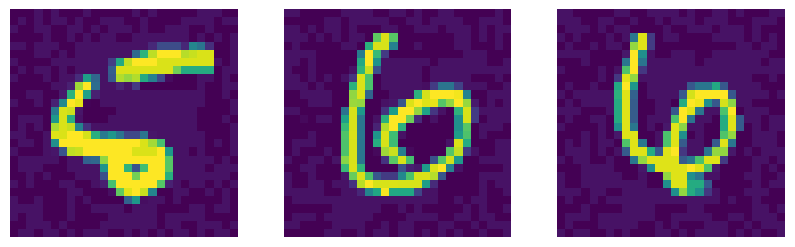

Epsilon: 0.05999999865889549. Verified accuracy on images: 52.9


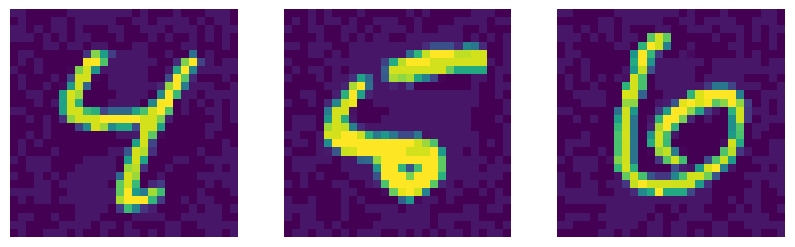

Epsilon: 0.07000000029802322. Verified accuracy on images: 45.74


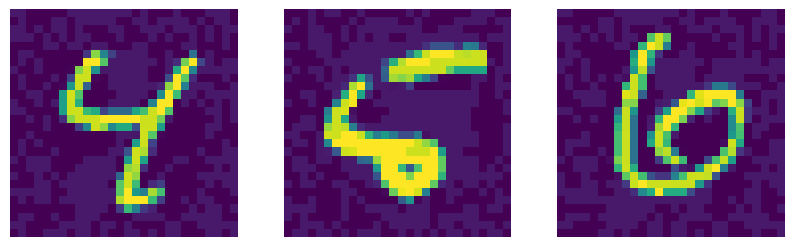

Epsilon: 0.07999999821186066. Verified accuracy on images: 38.77


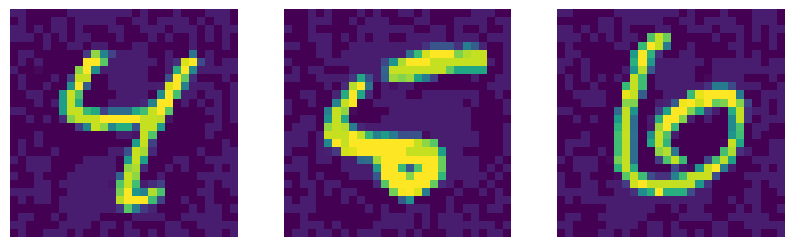

Epsilon: 0.09000000357627869. Verified accuracy on images: 31.99


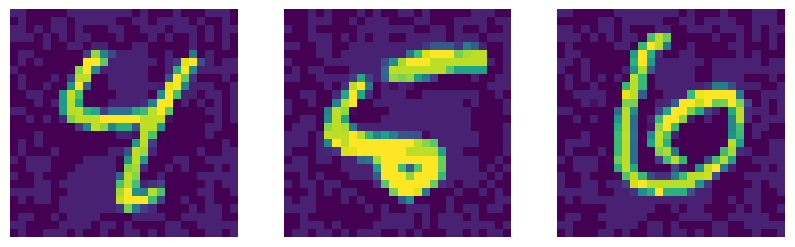

Epsilon: 0.10000000149011612. Verified accuracy on images: 25.99


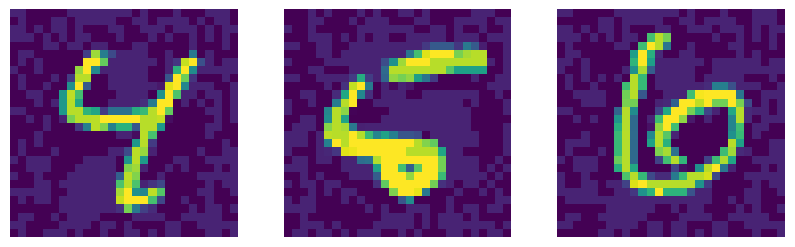

In [25]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

model.to("mps")
model.eval()
factory = BoundModelFactory()
bound_model = factory.build(model).to(device)

def push_interval(images, labels, eps):
    bounds2 = bound_model.ibp(HyperRectangle.from_eps(images, eps))

    # "Output layer" where we determine fy (x′)−fj (x′) for each j ̸= y.
    # fy(x)
    fy_x = bounds2.lower.gather(1, labels.unsqueeze(1))

    # computing fy(x) - fj(x)
    differences = fy_x - bounds2.upper

    # we need to account for the fact that the previous line does this for y = j. replace with +inf.
    differences = differences.scatter(1, labels.unsqueeze(1), float('inf'))

    # determine if all non-negatuve
    verified = (differences >= 0).all(dim=1)

    return verified


def test_interval(eps):

    correct = 0
    total = 0
    failed_images = []
    max_failed_images = 3

    for data in test_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        with torch.no_grad():
            verified = push_interval(images, labels, eps)
        total += labels.size(0)
        correct += verified.sum().item()


        # Let's find some adversarial examples
        not_verified = torch.where(~verified)[0]
        steps = 10
        alpha = 2.5 * eps / steps

        if len(failed_images) < max_failed_images:

            if len(not_verified) > 0:
                x_adv = pgd_linf(model, images[not_verified], labels[not_verified], eps, alpha, steps, False)

                with torch.no_grad():
                    successful_attack = model(x_adv).argmax(dim=1) != labels[not_verified]
                
                for img in x_adv[successful_attack]:
                    # Add at most 3 adversarial examples
                    if len(failed_images) < max_failed_images:
                        failed_images.append(img.cpu())

    print(f'Epsilon: {eps}. Verified accuracy on images: {100 * correct / total}')
    return failed_images

for eps in torch.linspace(0.01, 0.1, 10):
    failed_images = test_interval(eps.item())

    if len(failed_images) >= 2: # need to have at least 2 examples otherwise plotting code fails
        fig, axes = plt.subplots(1, len(failed_images), figsize = (10, 12))
        for i in range(len(failed_images)):
            axes[i].imshow(failed_images[i].reshape(28, 28))
            axes[i].axis("off")
    plt.show()